In [1]:
import os
import sys

# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

print("Updated PATH to include MPI")
print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

Updated PATH to include MPI
MPI location: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin
PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



In [2]:
import os
import os.path as op
from functools import partial

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, average_dipoles
from hnn_core.optimization import Optimizer, add_opt_drives, set_params_opt_drives

import numpy as np

import pickle
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from scipy.stats import pearsonr

pathfig = os.path.join(os.getcwd(), 'figures')
pathgen = '/users/kduecker/hnn-data/'

n_procs = 1

--No graphics will be displayed.


In [3]:
initial_params = dict({'prox1_L2_basket_ampa': 0.001,
                    'prox1_L2_pyramidal_ampa': 0.15,
                    'prox1_L5_basket_ampa': 0.0,
                    'prox1_L5_pyramidal_ampa': 0.001,

                    'prox1_L2_basket_nmda': 0.01,
                    'prox1_L2_pyramidal_nmda': 0.05,
                    'prox1_L5_basket_nmda': 0.0075,
                    'prox1_L5_pyramidal_nmda': .0,

                    'dist1_L2_basket_ampa': 0.005,
                    'dist1_L2_pyramidal_ampa': 1,
                    'dist1_L5_pyramidal_ampa': 0.8,

                    'dist1_L2_basket_nmda': 0.0,
                    'dist1_L2_pyramidal_nmda': 0.5,
                    'dist1_L5_pyramidal_nmda': 0.1,

                    'prox2_L2_basket_ampa': 0.009,
                    'prox2_L2_pyramidal_ampa': 0.4,
                    'prox2_L5_basket_ampa': 0.006,
                    'prox2_L5_pyramidal_ampa': 0.2,

                    'prox2_L2_basket_nmda': 0.1,
                    'prox2_L2_pyramidal_nmda': 0.05,
                    'prox2_L5_basket_nmda': 0.005,
                    'prox2_L5_pyramidal_nmda':  0.8,
                    
                    'prox1_mu': 20,
                    'prox1_sigma': 6,
                    'prox1_num_spikes': 1,
                    'dist1_mu': 62,
                    'dist1_sigma': 7,
                    'dist1_num_spikes': 2,
                    'prox2_mu': 95,
                    'prox2_sigma': 10,
                    'prox2_num_spikes': 1})


constraints = dict({'prox1_L2_basket_ampa': (-5., 1.),
                    'prox1_L2_pyramidal_ampa': (-5., 1.),
                    'prox1_L5_basket_ampa': (-5., 1.),
                    'prox1_L5_pyramidal_ampa': (-5., 1.),

                    'prox1_L2_basket_nmda': (0-5., 1.),
                    'prox1_L2_pyramidal_nmda': (-5., 1.),
                    'prox1_L5_basket_nmda': (-5., 1.),
                    'prox1_L5_pyramidal_nmda': (-5., 1.),

                    'dist1_L2_basket_ampa': (-5., 1.),
                    'dist1_L2_pyramidal_ampa': (-5., 1.),
                    'dist1_L5_pyramidal_ampa': (-5., 1.),

                    'dist1_L2_basket_nmda': (-5., 1.),
                    'dist1_L2_pyramidal_nmda': (-5., 1.),
                    'dist1_L5_pyramidal_nmda': (-5., 1.),

                    'prox2_L2_basket_ampa': (-5., 1.),
                    'prox2_L2_pyramidal_ampa': (-5., 1.),
                    'prox2_L5_basket_ampa': (-5., 1.),
                    'prox2_L5_pyramidal_ampa': (-5., 1.),

                    'prox2_L2_basket_nmda': (-5., 1.),
                    'prox2_L2_pyramidal_nmda': (-5., 1.),
                    'prox2_L5_basket_nmda': (-5., 1.),
                    'prox2_L5_pyramidal_nmda': (-5., 1.),
                    
                    'prox1_mu': (1, 50),
                    'prox1_sigma': (1, 20),
                    'prox1_num_spikes': (1, 3),
                    'dist1_mu': (50, 100),
                    'dist1_sigma': (1, 20),
                    'dist1_num_spikes': (1,3),
                    'prox2_mu': (80, 150),
                    'prox2_sigma': (1, 20),
                    'prox2_num_spikes': (1, 3)})

In [5]:
def set_up_drives_empty(net, tstop=200, n_prox=2, n_dist=1):
    prox_cell_type = ['L5_pyramidal', 'L5_basket', 'L2_pyramidal', 'L2_basket']
    dist_cell_type = ['L5_pyramidal', 'L2_pyramidal', 'L2_basket']
    default_range = {'mu': (0, tstop), 'sigma': (0, 20), 'ampa': (-5, 1), 'nmda': (-5, 1)}
    default_values = {'mu': tstop // 2, 'sigma': 2, 'ampa': -3, 'nmda': -3}

    prox_weights  = {cell_type: 0.0 for cell_type in prox_cell_type}
    dist_weights  = {cell_type: 0.0 for cell_type in dist_cell_type}

    prox_delays = {"L2_basket": 0.1, "L2_pyramidal": 0.1, "L5_basket": 1.0, "L5_pyramidal": 1.0,}
    dist_delays = {"L2_basket": 0.1, "L2_pyramidal": 0.1, "L5_pyramidal": 0.1}

    # Add proximal drives
    for idx in range(n_prox):
        name = f'prox{idx+1}'

        net.add_evoked_drive(name,
                             mu=0.0,
                             sigma=1.0,
                             numspikes=1,
                             location='proximal',
                             weights_ampa=prox_weights,
                             weights_nmda=prox_weights,
                             synaptic_delays=prox_delays)

    # Add distal drives
    for idx in range(n_dist):
        name = f'dist{idx+1}'

        net.add_evoked_drive(name,
                             mu=0.0,
                             sigma=1.0,
                             numspikes=1,
                             location='distal',
                             weights_ampa=dist_weights,
                             weights_nmda=dist_weights,
                             synaptic_delays=dist_delays)

In [6]:
data_url = f'{pathgen}MEG_detection_data/S1_SupraT.txt'
exp_dpl = read_dipole(data_url)

tstop = exp_dpl.times[-1]
scaling_factor = 1000
smooth_win = 5

In [8]:
net_base = duecker_ET_model()
set_up_drives_empty(net_base)
dt = 0.025
net_base._verbose = True


# Run optimization
max_iter = 10
optim = Optimizer(net_base, tstop=tstop, constraints=constraints, solver='cma',
                set_params=set_params_opt_drives, initial_params=initial_params, max_iter=max_iter, obj_fun="dipole_rmse_corr")
                
popsize = 5  # number of simulations per epoch, bigger is often better but very expensive!
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
        optim.fit(target=exp_dpl, n_trials=1, scale_factor=scaling_factor,
                smooth_window_len=smooth_win, dt=dt, popsize=popsize, bsl_cor="duecker")

(2_w,5mirr1)-aCMA-ES (mu_w=1.6,w_1=73%) in dimension 31 (seed=269504, Wed Feb  4 17:34:31 2026)
(5, 31)


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
exp(823.773) out of range, returning exp(700)
exp(1619.67) out of range, returning exp(700)
exp(1123.56) out of range, returning exp(700)
exp(1123.56) out of range, returning exp(700)
No more errno warnings during this execution
exp(3950.57) out of range, returning exp(700)
exp(4227.95) out of range, returning exp(700)
exp(11624.9) out of range, returning exp(700)
exp(4227.95) out of range, returning exp(700)
No more errno warnings during this execution
exp(925.086) out of range, returning exp(700)
exp(1820.6) out of range, returning exp(700)
exp(1263.75) out of range, returning exp(700)
exp(1263.75) out of range, returning exp(700)
No more errno warnings during this execution
exp(1290.79) out of range, returning exp(700)
exp(762.24) out of range, returning exp(700)
exp(966.079) out of range, returning exp(700)
exp(1901.91)

Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Mean Loss: 164.59; Min Loss: 145.19
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      5 1.451924148134858e+02 1.0e+00 9.08e-01  1e-02  5e-01 1:38.2
(5, 31)


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
exp(933.974) out of range, returning exp(700)
exp(834.648) out of range, returning exp(700)
exp(2516.18) out of range, returning exp(700)
exp(899.928) out of range, returning exp(700)
exp(4976.27) out of range, returning exp(700)
exp(3465.37) out of range, returning exp(700)
No more errno warnings during this execution
exp(1370.09) out of range, returning exp(700)
exp(809.129) out of range, returning exp(700)
exp(1772.39) out of range, returning exp(700)
exp(3501.09) out of range, returning exp(700)
No more errno warnings during this execution
exp(886.967) out of range, returning exp(700)
exp(891.634) out of range, returning exp(700)
No more errno warnings during this execution
exp(2511.53) out of range, returning exp(700)
exp(898.259) out of range, returning exp(700)
exp(4967.06) out of range, returning exp(700)
exp(3458.9

Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Mean Loss: 151.64; Min Loss: 119.08
    2     10 1.190766639649296e+02 1.0e+00 8.33e-01  1e-02  4e-01 2:52.4
(5, 31)


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
exp(1301.94) out of range, returning exp(700)
exp(901.888) out of range, returning exp(700)
exp(901.888) out of range, returning exp(700)
exp(901.888) out of range, returning exp(700)
No more errno warnings during this execution
exp(905.973) out of range, returning exp(700)
exp(809.573) out of range, returning exp(700)
exp(1600.85) out of range, returning exp(700)
exp(1714.88) out of range, returning exp(700)
exp(4713.91) out of range, returning exp(700)
exp(1714.88) out of range, returning exp(700)
No more errno warnings during this execution
exp(856.775) out of range, returning exp(700)
exp(1685.12) out of range, returning exp(700)
exp(1169.22) out of range, returning exp(700)
exp(1169.22) out of range, returning exp(700)
No more errno warnings during this execution
exp(967.626) out of range, returning exp(700)
exp(864.78

Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Mean Loss: 140.24; Min Loss: 119.82
    3     15 1.198212389115753e+02 1.0e+00 7.81e-01  1e-02  4e-01 4:24.9
(5, 31)


--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
--No graphics will be displayed.
exp(1673.16) out of range, returning exp(700)
exp(988.341) out of range, returning exp(700)
exp(1194.9) out of range, returning exp(700)
exp(705.54) out of range, returning exp(700)
No more errno warnings during this execution
exp(1684.38) out of range, returning exp(700)
exp(3326.54) out of range, returning exp(700)
exp(2314.4) out of range, returning exp(700)
exp(2314.4) out of range, returning exp(700)
No more errno warnings during this execution
exp(926.888) out of range, returning exp(700)
exp(828.303) out of range, returning exp(700)
exp(2023.06) out of range, returning exp(700)
exp(722.645) out of range, returning exp(700)
exp(3998.26) out of range, returning exp(700)
exp(2783.04) out of range, returning exp(700)
No more errno warnings during this execution
exp(1008.69) out of range, returning exp(700)
exp(1068.6) ou

Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Mean Loss: 286.06; Min Loss: 91.48
    4     20 9.148024039800524e+01 1.0e+00 7.45e-01  1e-02  4e-01 6:06.6
(5, 31)
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Mean Loss: 96.52; Min Loss: 82.49
    5     25 8.248755019774792e+01 1.1e+00 7.28e-01  1e-02  4e-01 7:40.3
(5, 31)
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Applying calcium model baseline correction
Mean Loss: 87.16; Min Loss: 77.27
    6     30 7.726734551533465e+01 1.1e+00 7.23e-01  1e-02  4e-01 9:13.4
(5, 31)
Applying 

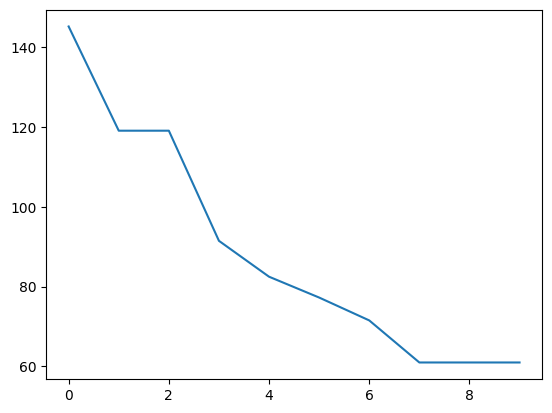

In [9]:
plt.plot(optim.obj_)

In [10]:
dpl_opt = simulate_dipole(optim.net_, tstop=tstop, dt=dt, bsl_cor="duecker")[0]
dpl_opt.scale(scaling_factor).smooth(smooth_win)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.05 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying calcium model baseline correction


In [17]:
from hnn_core.dipole import _corr, _rmse

In [19]:
inv_corr = _corr(dpl_opt, exp_dpl, tstop=exp_dpl.times[-1])
actual_corr = 1-inv_corr


In [20]:
actual_rmse = _rmse(dpl_opt, exp_dpl, tstop=exp_dpl.times[-1])

In [21]:
actual_rmse*(2-actual_corr)

np.float64(59.938364920870924)

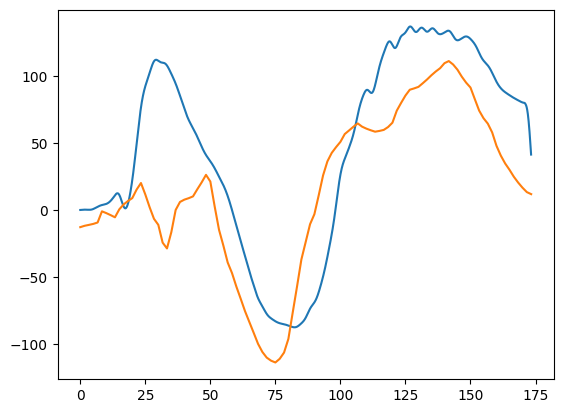

In [12]:
plt.plot(dpl_opt.times, dpl_opt.data['agg'])
plt.plot(exp_dpl.times, exp_dpl.data['agg'])

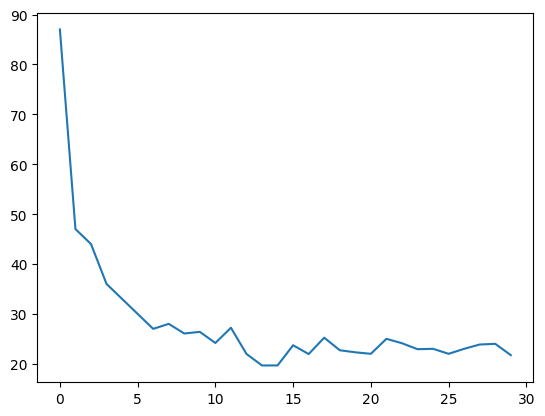

In [40]:
plt.plot(np.arange(30), np.array((87, 47, 44, 36, 33, 30, 27, 28, 26.07, 26.4, 24.17, 27.22, 21.97, 19.66, 19.67, 23.71, 21.95, 25.23, 22.71, 22.30, 22.0, 25, 24.12, 22.92, 23, 22, 23, 23.86, 24, 21.73)))